## Layer 3: Agent - The Complex Controller
> The agent loop in one function call

Agents use language models to choose a sequence of actions to take. A basic agent works in the following manner:
* Given a prompt an agent uses an LLM to request an action to take (e.g., a tool to run).
* The agent executes the action (e.g., runs the tool), and receives an observation.
* The agent returns the observation to the LLM, which can then be used to generate the next action.
* When the agent reaches a stopping condition, it returns a final return value.

Why Use a Prebuilt Agent?
 * **One Call**: A model, tools and a system prompt. The agent loop arrives prebuilt.
 * **A LangGraph graph**: It returns the same compiled graph you wires by hand on `2_langgraph_orchestration.ipynb`
 * **Trade-Offs**: Climb a layer: Hand control to the framework vs write far less code
 * **Batteries Included**: Memory, structures output, middleware and MCOP ready for projects.

### Additional features we'll explore:
* **The simpest agent**: A model and a prompt in one call, like OpenAI Agents SDK.
* **`ainvoke`**: Invoke's async equivalent; await it, nothing else changes
* **Middleware**: Your hooks insed the loop
* **MCP**: Sever tools drive a real browser before your yeas

### Pre-setup: Node and Playwright
* Node.js: The LTS JavaScript runtime; Its npx command runs packages on demand
* Playwright: Microsoft's browser automation; It open and drives real Chrome. Nothing to insatll, the npx fetches the MCP serve on first run.

In [ ]:
import os
import warnings

warnings.filterwarnings("ignore", category=DeprecationWarning)

from dotenv import load_dotenv
from IPython.display import Image, display

#langChain Agents 
from langchain.agents import create_agent
from langchain.agents.middleware import wrap_tool_call

# LangChain MCP
from langchain.mcp import MCPAdapter
from langchain_core.tools import tool
from langgraph.checkpoint.memory import MemorySaver
from pydantic import BaseModel, Field

load_dotenv(override=True)
NTFY_TOPIC_URL = os.getenv("NTFY_TOPIC_URL")

# -------------------- Clean all base urls --------------------
os.environ.pop("GROQ_BASE_URL", None)
os.environ.pop("GEMINI_BASE_URL", None)
os.environ.pop("OPENROUTER_BASE_URL", None)
os.environ.pop("GLM_Z_BASE_URL", None)
os.environ.pop("OLLAMA_BASE_URL", None)
os.environ.pop("OLLAMA_API_BASE", None)

/var/folders/j9/pgwv4z1143q_6zprltzrvf9w0000gn/T/ipykernel_22651/3121411890.py:15: LangChainBetaWarning: `langchain.mcp` is in beta. It is actively being worked on, so the API may change.
  from langchain.mcp import MCPAdapter


'http://localhost:11434/v1'

## Part 1: the simplest agent
An agent in its plainest form is a model with a prompt. We pass the model as a string in the form `provider:model`, and a system prompt to set its character.

In [ ]:
# Creates an agent graph that calls tools in a loop until a stopping condition is met.
agent = create_agent(
    model="groq:openai/gpt-oss-20b",            # Provide:model_name sometimes is like this one provider:owner/model_name
    system_prompt="You are a helpful assistant who answers concisely.",
)

result = agent.invoke({"messages": [{"role": "user", "content": "What is the Model Context Protocol, in two sentences?"}]})
print(result["messages"][-1].content)

The Model Context Protocol is a standardized framework that defines how to structure and exchange contextual information between AI models and their environment, ensuring consistent understanding and interpretation. It specifies data formats, communication patterns, and versioning to facilitate interoperability and maintain model performance across different systems.


### And its async twin: ainvoke
Everything in LangChain that can `invoke` can also `ainvoke`: same arguments, same result, awaited. You know asyncio well from earlier in the course, so there is nothing new to learn; this is simply the right way to call an agent from async code. It will matter at the end of this lab, where the browser tools only speak async.

In [8]:
result = await agent.ainvoke({"messages": [{"role": "user", "content": "In one sentence: why does async code suit agents so well?"}]})
print(result["messages"][-1].content)

Async code suits agents because it lets them pause while waiting for external events or resources, freeing the thread to handle other agents without blocking.


## Part 2: tools
To make the agent useful, we give it tools. These are the same `@tool` functions. We pass them in a list, and the agent runs the whole tool loop for us.

In [2]:
@tool
def get_weather(city: str) -> str:
    """Return today's weather for a city."""
    pretend = {"London": "rainy, 14 degrees", "Rome": "sunny, 27 degrees"}
    return pretend.get(city, "clear, 20 degrees")

@tool
def get_population(city: str) -> str:
    """Return the population of a city."""
    pretend = {"London": "8.9 million", "Rome": "2.8 million"}
    return pretend.get(city, "unknown")

agent = create_agent(
    model="google_genai:gemini-2.5-flash-lite",
    tools=[get_weather, get_population],
    system_prompt="You are a travel assistant. Use your tools to answer questions about cities.",
)

result = agent.invoke({"messages": [{"role": "user", "content": "What is the weather and population of Rome?"}]})
print(result["messages"][-1].content)

Both GOOGLE_API_KEY and GEMINI_API_KEY are set. Using GOOGLE_API_KEY.


The weather in Rome is sunny and 27 degrees. The population of Rome is 2.8 million.


## The reveal: it is a LangGraph graph
Now that our agent has tools, let us draw it. Because `create_agent` returns a compiled LangGraph graph, we can render it. Look at the shape: a model node, a tools node, and the conditional loop between them. This is the graph you built by hand on `2_langgraph_orchestration.ipynb`, handed to you in one line.

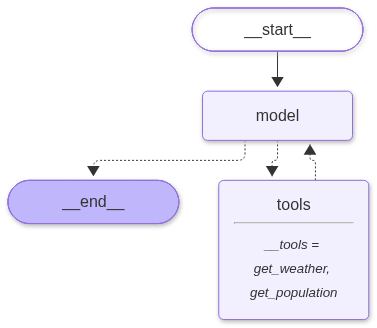

In [12]:
display(Image(agent.get_graph().draw_mermaid_png()))

## Part 3: Memory
By default each call to `invoke` is a fresh start. To remember a conversation we give the agent a checkpointer, exactly as we did with the graph yesterday, and pass a `thread_id` so it knows which conversation we mean.

In [16]:
memory_agent = create_agent(
    model="openrouter:cohere/north-mini-code:free",   # https://openrouter.ai/models?variant=free
    tools=[get_weather],
    checkpointer=MemorySaver(),
)

config = {"configurable": {"thread_id": "trip-planning"}}
memory_agent.invoke({"messages": [{"role": "user", "content": "I am planning a trip to London."}]}, config=config)
result = memory_agent.invoke({"messages": [{"role": "user", "content": "What is the weather like where I am going on my trip?"}]}, config=config)
print(result["messages"][-1].content)

The weather in London is currently rainy with a temperature of 14°C (about 57°F). That's quite mild for London, but definitely on the cooler and wetter side. 

For your trip planning, I'd recommend:
- Bringing a waterproof jacket or umbrella
- Packing layers since it's mild but not warm
- Comfortable walking shoes that can handle wet conditions
- Maybe a light sweater or cardigan for the cooler temperatures

Would you like me to help you with any other aspects of your London trip planning?


## Part 4: structured output
When you want a typed object back rather than prose, pass a Pydantic model as `response_format`. The agent still does its work and uses its tools, then fills in your object. You read it from the `structured_response` key.

In [5]:
class CityReport(BaseModel):
    city: str = Field(description="The city name")
    weather: str = Field(description="A short weather description")
    population: str = Field(description="The population")

report_agent = create_agent(
    model="ollama:gemma4:12b",
    tools=[get_weather, get_population],
    response_format=CityReport,
)

result = report_agent.invoke({"messages": [{"role": "user", "content": "Give me a report on London."}]})
report = result["structured_response"]
print(report)
print("Just the weather:", report.weather)

city='London' weather='rainy, 14 degrees' population='8.9 million'
Just the weather: rainy, 14 degrees


## Part 5: Middleware
Middleware is a powerful feature to shape an agent's behavior. It lets you run your own code at fixed points in the loop: before the model is called, after it answers, or around each tool call.

Here is a small piece of custom middleware that prints every tool call as it happens, so you can watch the agent at work. The `@wrap_tool_call` decorator wraps each tool call: we log it, then call `handler` to let it proceed.

In [7]:
@wrap_tool_call
def log_tool_calls(request, handler):
    call = request.tool_call
    print(f"  [middleware] calling {call['name']} with {call['args']}")
    return handler(request)

watched_agent = create_agent(
    model="ollama:gemma4:12b",
    tools=[get_weather, get_population],
    system_prompt="You are a travel assistant. Use your tools.",
    middleware=[log_tool_calls],
)

result = watched_agent.invoke({"messages": [{"role": "user", "content": "Weather and population of London and Rome?"}]})
print("\nFinal answer:", result["messages"][-1].content)

  [middleware] calling get_population with {'city': 'London'}
  [middleware] calling get_weather with {'city': 'London'}
  [middleware] calling get_weather with {'city': 'Rome'}
  [middleware] calling get_population with {'city': 'Rome'}

Final answer: The current weather in London is rainy at 14°C, and it has a population of approximately 8.9 million. In Rome, it's currently sunny with a temperature of 27°C, and the population is about 2.8 million.


LangChain also ships a range of ready made middleware, including `SummarizationMiddleware` to keep long conversations within the context window, `PIIMiddleware` to redact sensitive data, retry and call-limit middleware, and `HumanInTheLoopMiddleware` to pause for human approval.

## Before Part 6: Node and Playwright

The last part of this lab uses tools that live in a separate program, an MCP server, and that program runs on Node. Two quick checks before we start.

First, Node itself; you want v22 or later. If the cell below fails, install Node with one command:

- **Windows**, in PowerShell: `winget install OpenJS.NodeJS.LTS`
- **Mac**, in Terminal: `brew install node`
- **Linux**, or if neither works for you: see the guide at [setup/SETUP-node.md](../setup/SETUP-node.md)

After installing, quit Cursor completely and start it again, then reopen this notebook and re-run the lab from the top. That full restart matters: a freshly installed Node is invisible to a notebook that was already running, and restarting just the kernel is not enough.

In [8]:
!node --version
!npx --version

v25.9.0
11.13.0


Second, Playwright, Microsoft's browser automation framework. There is nothing to install: `npx` fetches it on demand, and it drives the copy of Chrome already on your machine. Chrome does not need to be running; Playwright launches its own.

The cell below proves the whole chain with no AI involved at all: Node runs Playwright, Playwright opens Chrome, loads Hacker News, and saves a screenshot. The first run takes a little longer while npx downloads the package.

If it complains that Chrome is not found, either install Chrome normally or run `npx playwright install chrome` in a terminal, then try again.

⠙⠹⠸⠼⠴⠦⠧⠇⠏⠋⠙⠹⠸⠼⠴⠦⠧⠇⠏⠋⠙⠹⠸⠼⠴⠦⠧⠇⠏⠋⠙⠹⠸⠼⠴⠦⠧⠇⠏⠋⠙⠹⠸⠼⠴⠦⠧⠇⠏⠋⠙⠹⠸⠼⠴⠦⠧⠇⠏⠋⠙⠹⠸⠼⠴⠦⠧⠇⠏⠋⠙⠹⠸⠼⠴⠦⠧⠇⠏Navigating to https://news.ycombinator.com
Capturing screenshot into playwright_check.png
⠙

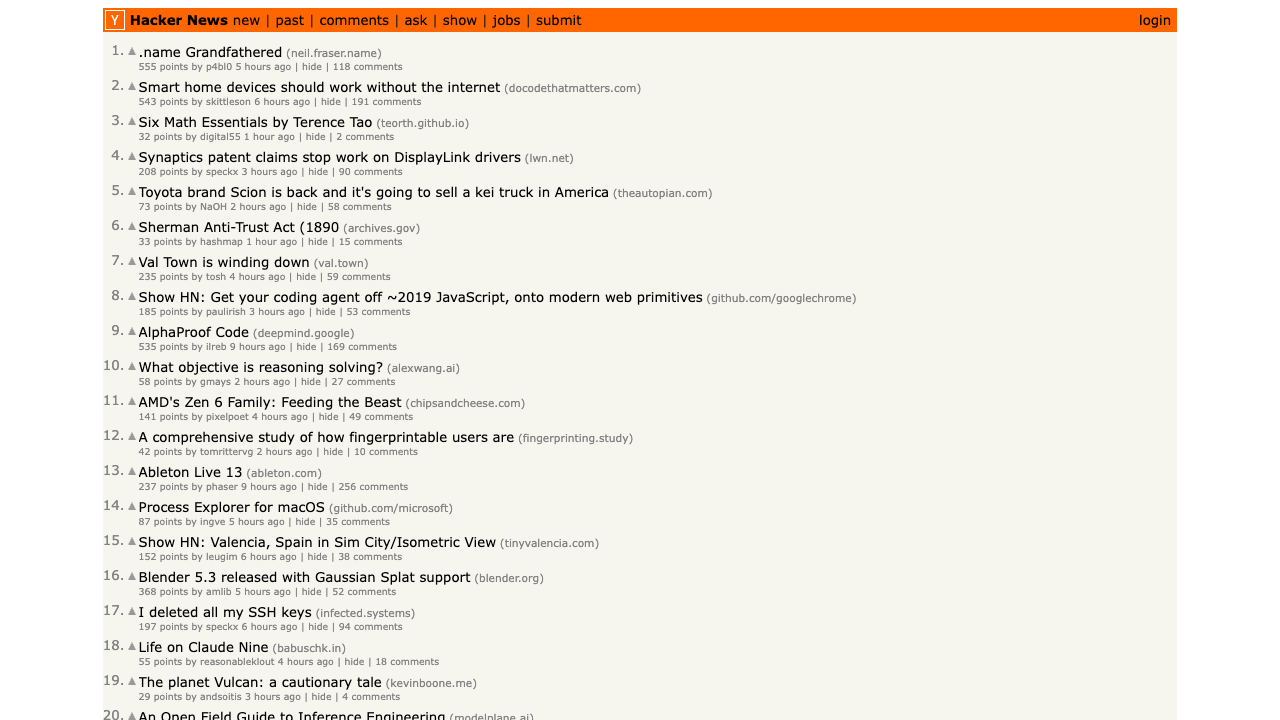

In [9]:
!npx -y playwright@latest screenshot --channel=chrome https://news.ycombinator.com playwright_check.png
display(Image("playwright_check.png"))

## Part 6: an MCP server, and a real browser
Tools do not have to be Python functions you write. The Model Context Protocol is a standard way for agents to use tools that live in a separate server. LangChain loads those tools with [MCPAdapter](https://docs.langchain.com/oss/python/langchain/mcp), and from the agent's point of view they are just tools like any other.

MCPAdapter infers the transport from the target you provide. A target can be any of the following:
* An http/https URL (str): reached over Streamable HTTP.
* A script path (Path): launched as a subprocess over stdio.
* A transport object (StreamableTransport): a preconfigured transport object. See [Client Transports](https://gofastmcp.com/docs/clients/transports).
* An in-process FastMCP server: connected in memory, without a subprocess or socket.
* An MCPConfig dict ({"mcpServers": {...}}): several servers behind one adapter. See [Connections](https://docs.langchain.com/oss/python/langchain/mcp/connections#multiple-servers).
* A prebuilt [fastmcp.Client](https://gofastmcp.com/docs/clients/client#protocol-negotiation): for full control over transport, caching, and protocol negotiation.

We will connect to Microsoft's Playwright MCP server, which drives the same real browser you just smoke-tested. It runs headed by default, so you can watch it work; on a Linux box with no display it quietly falls back to headless. Because these tools talk to a separate process, they are async, so we load them with `await` and run the agent with `ainvoke`, which you met in Part 1.

### One adjustment for Windows
When Python launches another program, it hands that program a place to write its error messages. Inside a Jupyter notebook on Windows, that place is not a real file, and the library that launches MCP servers trips over it (a known issue in the MCP Python SDK, which only shows up in notebooks, never in ordinary Python scripts). The cell below points the MCP server's error log somewhere safe before we connect. On Mac and Linux it does nothing at all, so run it either way and carry on.

In [ ]:
import asyncio
import sys

# Fix for Windows issues in Jupyter notebooks
if sys.platform == "win32":
    # 1. Use ProactorEventLoop for subprocess support
    if not isinstance(asyncio.get_event_loop_policy(), asyncio.WindowsProactorEventLoopPolicy):
        asyncio.set_event_loop_policy(asyncio.WindowsProactorEventLoopPolicy())
    
    # 2. Redirect stderr to avoid fileno() error when launching MCP servers
    if "ipykernel" in sys.modules:
        sys.stderr = sys.__stderr__

In [11]:
config = {
    "mcpServers": {
        "playwright": {
            "command": "npx",
            "args": ["-y", "@playwright/mcp@latest", "--isolated"],
        }
    }
}

async with MCPAdapter(config) as adapter:
    browser_tools = await adapter.list_tools()

    print(f"Loaded {len(browser_tools)} browser tools:")
    for t in browser_tools:
        print(" -", t.name)

Loaded 25 browser tools:
 - browser_close
 - browser_resize
 - browser_console_messages
 - browser_handle_dialog
 - browser_emulate_media
 - browser_evaluate
 - browser_file_upload
 - browser_drop
 - browser_find
 - browser_fill_form
 - browser_press_key
 - browser_type
 - browser_navigate
 - browser_navigate_back
 - browser_network_requests
 - browser_network_request
 - browser_run_code_unsafe
 - browser_take_screenshot
 - browser_snapshot
 - browser_click
 - browser_drag
 - browser_hover
 - browser_select_option
 - browser_tabs
 - browser_wait_for


Now we hand those browser tools to an ordinary `create_agent` and ask it to visit Hacker News and report what it finds. Watch the browser window open and navigate on its own.

In [13]:
browser_agent = create_agent(
    model="ollama:gemma4:12b",
    tools=browser_tools,
    system_prompt="You are a web research assistant. Use the browser tools to complete the task, then report clearly.",
)

result = await browser_agent.ainvoke({"messages": [{"role": "user",
    "content": "Go to https://news.ycombinator.com and tell me the titles of the top three stories on the front page."}]})
print(result["messages"][-1].content)

The top three stories on the Hacker News front page are:

1.  **Grandfathered** (from neil.fraser.name)
2.  **Smart home devices should work without the internet** (from docodethatmatters.com)
3.  **Toyota brand Scion is back and it's going to sell a kei truck in America** (from theautopian.com)
